In [4]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

data = pd.read_csv('cifar-10.csv')

data.head()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_3063,pixel_3064,pixel_3065,pixel_3066,pixel_3067,pixel_3068,pixel_3069,pixel_3070,pixel_3071,label
0,59,43,50,68,98,119,139,145,149,149,...,58,65,59,46,57,104,140,84,72,6
1,154,126,105,102,125,155,172,180,142,111,...,42,67,101,122,133,136,139,142,144,9
2,255,253,253,253,253,253,253,253,253,253,...,83,80,69,66,72,79,83,83,84,9
3,28,37,38,42,44,40,40,24,32,43,...,39,59,42,44,48,38,28,37,46,4
4,170,168,177,183,181,177,181,184,189,189,...,88,85,82,83,79,78,82,78,80,1


In [5]:
x = data.drop('label', axis=1).values
y = data['label'].values
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)


Training data: (40000, 3072)
Testing data: (10000, 3072)


In [6]:
x_train = x_train/255.0
x_test = x_test/255.0

model = keras.Sequential([
    layers.Input(shape=(3072,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer = keras.optimizers.SGD(learning_rate=0.01),
    loss = "sparse_categorical_crossentropy",
    metrics = ['accuracy']
)

history = model.fit(x_train, y_train, epochs=11, batch_size=32, validation_split=0.2)

loss, accuracy = model.evaluate(x_test, y_test)

print("Loss : ", loss)
print("Accuracy : ", accuracy)

Epoch 1/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 17s 16ms/step - accuracy: 0.2968 - loss: 1.9548 - val_accuracy: 0.3435 - val_loss: 1.8300
Epoch 2/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.3655 - loss: 1.7767 - val_accuracy: 0.3720 - val_loss: 1.7390
Epoch 3/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - accuracy: 0.3950 - loss: 1.6996 - val_accuracy: 0.3909 - val_loss: 1.6823
Epoch 4/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.4142 - loss: 1.6461 - val_accuracy: 0.4026 - val_loss: 1.6500
Epoch 5/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - accuracy: 0.4306 - loss: 1.6042 - val_accuracy: 0.4168 - val_loss: 1.6247
Epoch 6/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.4455 - loss: 1.5693 - val_accuracy: 0.4309 - val_loss: 1.5997
Epoch 7/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - accuracy: 0.4588 - loss: 1.5396 - val_accuracy: 0.4350 - val_loss: 1.5829
Epoch 8/11
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.4674 -

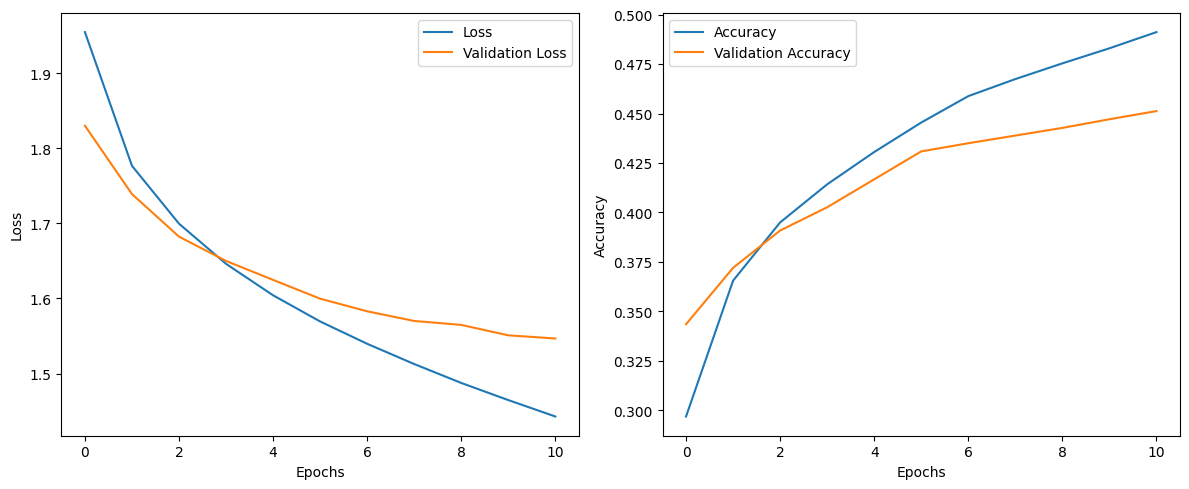

In [8]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label="Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.xlabel('Epochs')
plt.ylabel("Loss")
plt.legend()
# plt.grid(True)

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label="Accuracy")
plt.plot(history.history['val_accuracy'], label="Validation Accuracy")
plt.xlabel('Epochs')
plt.ylabel("Accuracy")
plt.legend()
# plt.grid(True)

plt.tight_layout()
plt.show()